## Experimento histórico

Este notebook conserva los cálculos y salidas previos a la revisión temporal. No usar sus métricas como conclusiones finales. El flujo vigente está en `ML.train`, `protocol.json` y `ML_Resultados_Finales.ipynb`. Las fechas y etiquetas se unifican en `features.py`.


In [5]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from imblearn.over_sampling import SMOTE
from lightgbm import LGBMClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split

# ==========================
# 1. CARGA DEL DATASET
# ==========================

df = pd.read_csv("./Datasets/train.csv")

df["Order Date"] = pd.to_datetime(
    df["Order Date"],
    format="mixed"
)

df["Ship Date"] = pd.to_datetime(
    df["Ship Date"],
    format="mixed"
)

df_clean = df.copy()

print("Registros:", len(df_clean))
print("Clientes:", df_clean["Customer ID"].nunique())
print("Pedidos:", df_clean["Order ID"].nunique())

Registros: 9800
Clientes: 793
Pedidos: 4922


In [6]:
# ==========================
# 2. CREACIÓN DE CHURN
# ==========================

fecha_observacion = df_clean["Order Date"].max()

rfm = (
    df_clean.groupby("Customer ID")
    .agg(
        Recency=(
            "Order Date",
            lambda x: (fecha_observacion - x.max()).days
        ),
        Frequency=("Order ID", "nunique"),
        Monetary=("Sales", "sum")
    )
    .reset_index()
)

rfm["Churn"] = (
    rfm["Recency"] > 180
).astype(int)

rfm.head()

,Customer ID,Recency,Frequency,Monetary,Churn
0,AA-10315,184,5,5563.560,1
1,AA-10375,48,9,1056.390,0
2,AA-10480,259,4,1790.512,1
3,AA-10645,233,6,5086.935,1
4,AB-10015,445,3,886.156,1


In [7]:
# ==========================
# 3. VARIABLES PREDICTORAS
# ==========================

rfm_features = (
    df_clean.groupby("Customer ID")
    .agg(
        Frequency=("Order ID", "nunique"),
        Monetary_Sum=("Sales", "sum"),
        Monetary_Mean=("Sales", "mean"),
        Monetary_Std=("Sales", "std"),
        Cat_Count=("Category", "nunique"),
        SubCat_Count=("Sub-Category", "nunique")
    )
    .reset_index()
)

rfm_features["Monetary_Std"] = (
    rfm_features["Monetary_Std"].fillna(0)
)

rfm_features = rfm_features.merge(
    rfm[["Customer ID", "Churn"]],
    on="Customer ID",
    how="left"
)

rfm_features.head()

,Customer ID,Frequency,Monetary_Sum,Monetary_Mean,Monetary_Std,Cat_Count,SubCat_Count,Churn
0,AA-10315,5,5563.560,505.778182,1157.990034,3,9,1
1,AA-10375,9,1056.390,70.426000,126.508857,3,7,0
2,AA-10480,4,1790.512,149.209333,176.229194,3,7,1
3,AA-10645,6,5086.935,282.607500,429.222188,3,9,1
4,AB-10015,3,886.156,147.692667,139.432371,3,5,1


In [8]:
# ==========================
# 4. TRAIN / TEST
# ==========================

X = rfm_features.drop(
    columns=["Customer ID", "Churn"]
)

y = rfm_features["Churn"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

print("\nVariables:")
print(X.columns)

print("\nDistribución entrenamiento:")
print(y_train.value_counts(normalize=True))

print("\nDistribución prueba:")
print(y_test.value_counts(normalize=True))

X_train: (634, 6)
X_test: (159, 6)

Variables:
Index(['Frequency', 'Monetary_Sum', 'Monetary_Mean', 'Monetary_Std',
       'Cat_Count', 'SubCat_Count'],
      dtype='str')

Distribución entrenamiento:
Churn
0    0.697161
1    0.302839
Name: proportion, dtype: float64

Distribución prueba:
Churn
0    0.698113
1    0.301887
Name: proportion, dtype: float64


In [9]:
model_lgbm = LGBMClassifier(
    n_estimators=100,
    max_depth=5,
    learning_rate=0.1,
    random_state=42,
    verbosity=-1
)

model_lgbm.fit(X_train, y_train)

y_pred_lgbm = model_lgbm.predict(X_test)
y_proba_lgbm = model_lgbm.predict_proba(X_test)[:, 1]

In [10]:
accuracy_lgbm = accuracy_score(y_test, y_pred_lgbm)
precision_lgbm = precision_score(y_test, y_pred_lgbm)
recall_lgbm = recall_score(y_test, y_pred_lgbm)
f1_lgbm = f1_score(y_test, y_pred_lgbm)
roc_auc_lgbm = roc_auc_score(y_test, y_proba_lgbm)

print("=== LIGHTGBM BASE ===")
print(f"Accuracy:  {accuracy_lgbm:.4f}")
print(f"Precision: {precision_lgbm:.4f}")
print(f"Recall:    {recall_lgbm:.4f}")
print(f"F1-Score:  {f1_lgbm:.4f}")
print(f"ROC-AUC:   {roc_auc_lgbm:.4f}")

print("\nReporte de clasificación:")
print(classification_report(y_test, y_pred_lgbm))

=== LIGHTGBM BASE ===
Accuracy:  0.6981
Precision: 0.5000
Recall:    0.3750
F1-Score:  0.4286
ROC-AUC:   0.6245

Reporte de clasificación:
              precision    recall  f1-score   support

           0       0.76      0.84      0.79       111
           1       0.50      0.38      0.43        48

    accuracy                           0.70       159
   macro avg       0.63      0.61      0.61       159
weighted avg       0.68      0.70      0.68       159



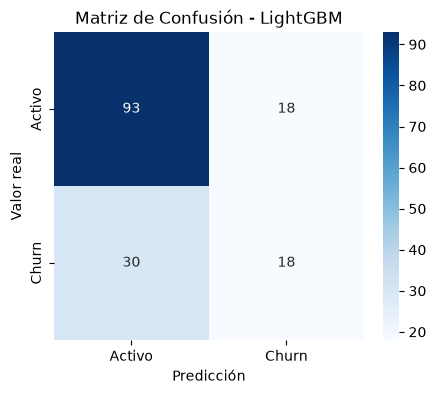

In [11]:
cm_lgbm = confusion_matrix(y_test, y_pred_lgbm)

plt.figure(figsize=(5, 4))

sns.heatmap(
    cm_lgbm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Activo", "Churn"],
    yticklabels=["Activo", "Churn"]
)

plt.title("Matriz de Confusión - LightGBM")
plt.xlabel("Predicción")
plt.ylabel("Valor real")
plt.show()

In [12]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

param_grid_lgbm = {
    "n_estimators": [100, 200, 300],
    "max_depth": [3, 5, 7],
    "learning_rate": [0.01, 0.05, 0.1],
    "num_leaves": [15, 31, 63]
}

grid_lgbm = GridSearchCV(
    estimator=LGBMClassifier(
        random_state=42,
        verbosity=-1
    ),
    param_grid=param_grid_lgbm,
    scoring="recall",
    cv=cv,
    n_jobs=-1,
    verbose=1
)

grid_lgbm.fit(X_train, y_train)

print("Mejores parámetros:")
print(grid_lgbm.best_params_)

print("\nMejor Recall en validación cruzada:")
print(grid_lgbm.best_score_)

Fitting 5 folds for each of 81 candidates, totalling 405 fits
Mejores parámetros:
{'learning_rate': 0.1, 'max_depth': 5, 'n_estimators': 200, 'num_leaves': 15}

Mejor Recall en validación cruzada:
0.41646423751686906


In [13]:
best_lgbm = grid_lgbm.best_estimator_

y_pred_best = best_lgbm.predict(X_test)
y_proba_best = best_lgbm.predict_proba(X_test)[:, 1]

accuracy_best = accuracy_score(y_test, y_pred_best)
precision_best = precision_score(y_test, y_pred_best)
recall_best = recall_score(y_test, y_pred_best)
f1_best = f1_score(y_test, y_pred_best)
roc_auc_best = roc_auc_score(y_test, y_proba_best)

print("=== LIGHTGBM OPTIMIZADO ===")
print(f"Accuracy:  {accuracy_best:.4f}")
print(f"Precision: {precision_best:.4f}")
print(f"Recall:    {recall_best:.4f}")
print(f"F1-Score:  {f1_best:.4f}")
print(f"ROC-AUC:   {roc_auc_best:.4f}")

print("\nReporte:")
print(classification_report(y_test, y_pred_best))

=== LIGHTGBM OPTIMIZADO ===
Accuracy:  0.6918
Precision: 0.4857
Recall:    0.3542
F1-Score:  0.4096
ROC-AUC:   0.6171

Reporte:
              precision    recall  f1-score   support

           0       0.75      0.84      0.79       111
           1       0.49      0.35      0.41        48

    accuracy                           0.69       159
   macro avg       0.62      0.60      0.60       159
weighted avg       0.67      0.69      0.68       159



In [14]:
smote = SMOTE(random_state=42)

X_train_smote, y_train_smote = smote.fit_resample(
    X_train,
    y_train
)

print("Antes de SMOTE:")
print(y_train.value_counts())

print("\nDespués de SMOTE:")
print(y_train_smote.value_counts())

Antes de SMOTE:
Churn
0    442
1    192
Name: count, dtype: int64

Después de SMOTE:
Churn
0    442
1    442
Name: count, dtype: int64


In [15]:
model_lgbm_smote = LGBMClassifier(
    n_estimators=100,
    max_depth=5,
    learning_rate=0.1,
    random_state=42,
    verbosity=-1
)

model_lgbm_smote.fit(
    X_train_smote,
    y_train_smote
)

y_pred_smote = model_lgbm_smote.predict(X_test)
y_proba_smote = model_lgbm_smote.predict_proba(X_test)[:, 1]

In [16]:
accuracy_smote = accuracy_score(y_test, y_pred_smote)
precision_smote = precision_score(y_test, y_pred_smote)
recall_smote = recall_score(y_test, y_pred_smote)
f1_smote = f1_score(y_test, y_pred_smote)
roc_auc_smote = roc_auc_score(y_test, y_proba_smote)

print("=== LIGHTGBM + SMOTE ===")
print(f"Accuracy:  {accuracy_smote:.4f}")
print(f"Precision: {precision_smote:.4f}")
print(f"Recall:    {recall_smote:.4f}")
print(f"F1-Score:  {f1_smote:.4f}")
print(f"ROC-AUC:   {roc_auc_smote:.4f}")

print("\nReporte:")
print(classification_report(y_test, y_pred_smote))

=== LIGHTGBM + SMOTE ===
Accuracy:  0.6918
Precision: 0.4902
Recall:    0.5208
F1-Score:  0.5051
ROC-AUC:   0.6749

Reporte:
              precision    recall  f1-score   support

           0       0.79      0.77      0.78       111
           1       0.49      0.52      0.51        48

    accuracy                           0.69       159
   macro avg       0.64      0.64      0.64       159
weighted avg       0.70      0.69      0.69       159



X_train: (634, 6)
X_test: (159, 6)


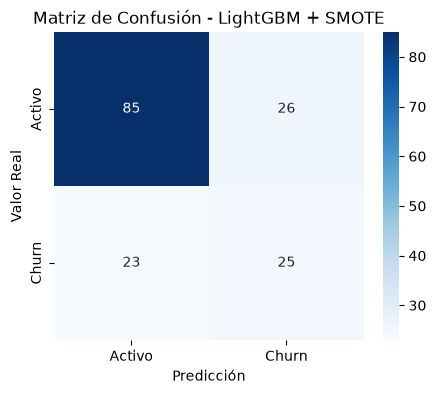

In [5]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from imblearn.over_sampling import SMOTE
from lightgbm import LGBMClassifier
from sklearn.metrics import confusion_matrix
from sklearn.model_selection import train_test_split

# ==========================
# 1. CARGAR DATOS
# ==========================

df = pd.read_csv("./Datasets/train.csv")

df["Order Date"] = pd.to_datetime(
    df["Order Date"],
    format="mixed"
)

df["Ship Date"] = pd.to_datetime(
    df["Ship Date"],
    format="mixed"
)

# ==========================
# 2. CREAR CHURN
# ==========================

fecha_observacion = df["Order Date"].max()

rfm = (
    df.groupby("Customer ID")
    .agg(
        Recency=(
            "Order Date",
            lambda x: (
                fecha_observacion - x.max()
            ).days
        ),
        Frequency=("Order ID", "nunique"),
        Monetary=("Sales", "sum")
    )
    .reset_index()
)

rfm["Churn"] = (
    rfm["Recency"] > 180
).astype(int)

# ==========================
# 3. VARIABLES DEL MODELO
# ==========================

rfm_features = (
    df.groupby("Customer ID")
    .agg(
        Frequency=("Order ID", "nunique"),
        Monetary_Sum=("Sales", "sum"),
        Monetary_Mean=("Sales", "mean"),
        Monetary_Std=("Sales", "std"),
        Cat_Count=("Category", "nunique"),
        SubCat_Count=("Sub-Category", "nunique")
    )
    .reset_index()
)

rfm_features["Monetary_Std"] = (
    rfm_features["Monetary_Std"].fillna(0)
)

rfm_features = rfm_features.merge(
    rfm[["Customer ID", "Churn"]],
    on="Customer ID",
    how="left"
)

# ==========================
# 4. TRAIN / TEST
# ==========================

X = rfm_features.drop(
    columns=["Customer ID", "Churn"]
)

y = rfm_features["Churn"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

# ==========================
# 5. SMOTE
# ==========================

smote = SMOTE(random_state=42)

X_train_smote, y_train_smote = smote.fit_resample(
    X_train,
    y_train
)

# ==========================
# 6. LIGHTGBM + SMOTE
# ==========================

model_lgbm_smote = LGBMClassifier(
    n_estimators=100,
    max_depth=5,
    learning_rate=0.1,
    random_state=42,
    verbosity=-1
)

model_lgbm_smote.fit(
    X_train_smote,
    y_train_smote
)

y_pred_lgbm_smote = model_lgbm_smote.predict(
    X_test
)

# ==========================
# 7. MATRIZ DE CONFUSIÓN
# ==========================

cm_lgbm_smote = confusion_matrix(
    y_test,
    y_pred_lgbm_smote
)

plt.figure(figsize=(5, 4))

sns.heatmap(
    cm_lgbm_smote,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Activo", "Churn"],
    yticklabels=["Activo", "Churn"]
)

plt.title("Matriz de Confusión - LightGBM + SMOTE")
plt.xlabel("Predicción")
plt.ylabel("Valor Real")

plt.show()

In [17]:
comparacion_lgbm = pd.DataFrame({
    "Modelo": [
        "LightGBM Base",
        "LightGBM Optimizado",
        "LightGBM + SMOTE"
    ],
    "Accuracy": [
        accuracy_lgbm,
        accuracy_best,
        accuracy_smote
    ],
    "Precision": [
        precision_lgbm,
        precision_best,
        precision_smote
    ],
    "Recall": [
        recall_lgbm,
        recall_best,
        recall_smote
    ],
    "F1-Score": [
        f1_lgbm,
        f1_best,
        f1_smote
    ],
    "ROC-AUC": [
        roc_auc_lgbm,
        roc_auc_best,
        roc_auc_smote
    ]
})

comparacion_lgbm

,Modelo,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,LightGBM Base,0.698113,0.500000,0.375000,0.428571,0.624531
1,LightGBM Optimizado,0.691824,0.485714,0.354167,0.409639,0.617117
2,LightGBM + SMOTE,0.691824,0.490196,0.520833,0.505051,0.674925


In [18]:
import joblib

joblib.dump(
    model_lgbm_smote,
    "modelo_lightgbm_smote.pkl"
)

print("Modelo LightGBM + SMOTE guardado correctamente.")

Modelo LightGBM + SMOTE guardado correctamente.
